In [1]:
import pandas as pd

In [7]:
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

In [8]:
df = pd.read_csv("../data/bank-additional-full.csv",sep=";")

In [9]:
fl = df["y"].value_counts()
print(fl)

y
no     36548
yes     4640
Name: count, dtype: int64


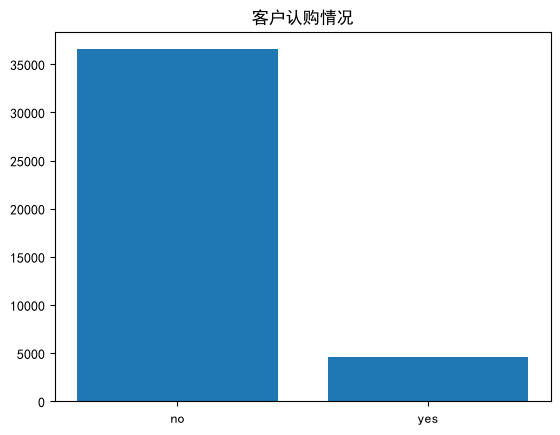

In [34]:
plt.bar(fl.index,fl.values)
plt.title("客户认购情况")
plt.savefig("../figures/01_认购情况.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
zhiye =df["job"].value_counts()
print(zhiye)

job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64


In [14]:
rgqk = (df["y"] == "yes")
df["rgqk"] = rgqk

In [22]:
rate = df.groupby("job")["rgqk"].mean()
rate = rate.sort_values(ascending=False)
print(rate)

job
student          0.314286
retired          0.252326
unemployed       0.142012
admin.           0.129726
management       0.112175
unknown          0.112121
technician       0.108260
self-employed    0.104856
housemaid        0.100000
entrepreneur     0.085165
services         0.081381
blue-collar      0.068943
Name: rgqk, dtype: float64


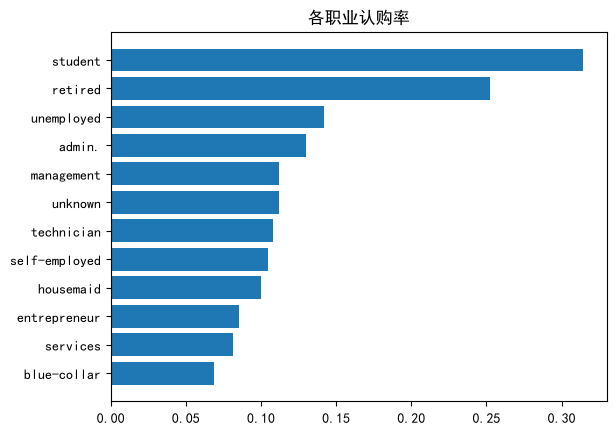

In [35]:
plt.barh(rate.index,rate.values)
plt.title("各职业认购率")
plt.gca().invert_yaxis()
plt.savefig("../figures/02_各职业认购率.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
df["fx"] = pd.cut(df["duration"],bins=[0,100,200,300,500,5000])
fx0 = df["fx"].value_counts()
print(fx0)

fx
(100, 200]     12733
(0, 100]       10023
(200, 300]      7224
(300, 500]      6276
(500, 5000]     4928
Name: count, dtype: int64


In [27]:
rate1 = df.groupby("fx")["rgqk"].mean()
print(rate1)

fx
(0, 100]       0.008081
(100, 200]     0.050185
(200, 300]     0.110465
(300, 500]     0.163161
(500, 5000]    0.425731
Name: rgqk, dtype: float64


C:\Users\27067\AppData\Local\Temp\ipykernel_29196\1871578337.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rate1 = df.groupby("fx")["rgqk"].mean()


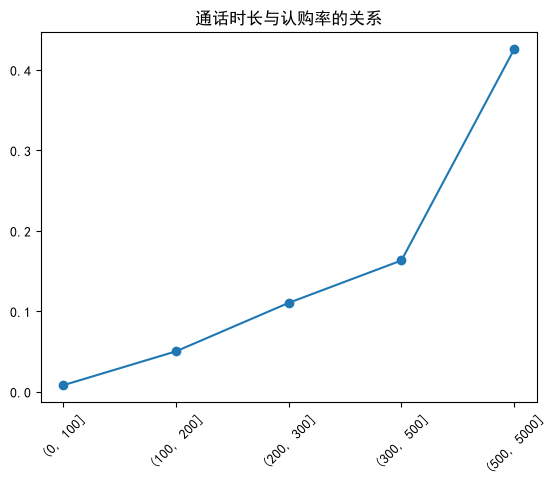

In [33]:
plt.plot(rate1.index.astype(str),rate1.values,marker="o")
plt.title("通话时长与认购率的关系")
plt.xticks(rotation=45)
plt.savefig("../figures/03_通话时长与认购率的关系.png", dpi=150, bbox_inches="tight")
plt.show()